<a href="https://colab.research.google.com/github/santiagodie/sudoku-vision-solver/blob/main/01_grid_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Grid detection

This notebook finds the 81 cells of a printed Sudoku board and marks which of them contain a clue. It uses only classical image processing: binarisation, contour extraction and simple shape filters.

The output is an 81-character string read row by row, where `?` marks a cell with a digit and `.` an empty cell. [Notebook 02](02_digit_recognition_and_solving.ipynb) replaces each `?` with the actual digit and solves the puzzle.

The three boards in `data/boards/` are printable puzzles from [sudoku-online.org](http://www.sudoku-online.org/imprimir-sudokus.php).

## Setup

In [1]:
# On Colab, clone the repository to get the data folder.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("data"):
    !git clone -q https://github.com/santiagodie/sudoku-vision-solver.git
    %cd sudoku-vision-solver

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

BOARDS = ["data/boards/sudoku1.png", "data/boards/sudoku2.png", "data/boards/sudoku3.png"]

In [3]:
# Helper provided in the course material: shows a BGR (colour) or grayscale image.
def show_image(image):
    if len(image.shape) == 3:
        plt.imshow(image[:, :, ::-1])
    else:
        plt.imshow(image, cmap="gray")
    plt.axis("off")
    plt.show()

## 1. Binarise the board

The board is black ink on a white background. An inverse threshold at 30 keeps only the near-black pixels (grid lines and digits) as white foreground, which is what `findContours` expects.

Board size: (372, 372)


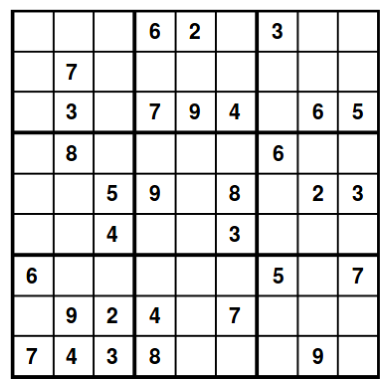

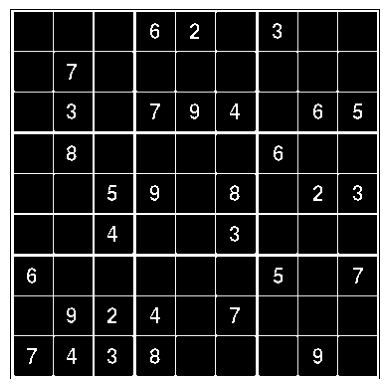

In [4]:
board = cv2.imread(BOARDS[0])
gray = cv2.cvtColor(board, cv2.COLOR_BGR2GRAY)
thresh = cv2.threshold(gray, 30, 255, cv2.THRESH_BINARY_INV)[1]

print("Board size:", board.shape[:2])
show_image(board)
show_image(thresh)

## 2. Extract contours

The cells are the holes *inside* the grid, so `cv2.RETR_EXTERNAL` would only return the outer border of the board. `cv2.RETR_LIST` returns every contour, inner and outer, without building a hierarchy.

131 contours found


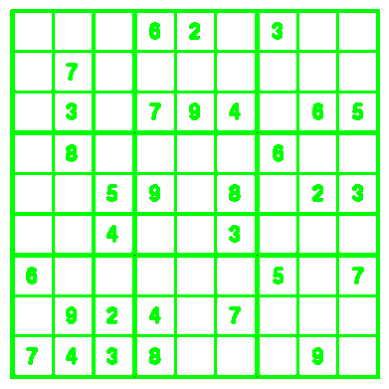

In [5]:
contours, _ = cv2.findContours(thresh.copy(), cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
print(f"{len(contours)} contours found")

preview = board.copy()
cv2.drawContours(preview, contours, -1, (0, 255, 0), 2)
show_image(preview)

## 3. Keep only the cells

Besides the cells, the contour list contains the digits, the 3×3 boxes and the board itself. Three shape properties separate the cells:

- **Solidity** (contour area / convex hull area) close to 1: a cell is a filled square, while digits have concave shapes.
- **Aspect ratio** close to 1: cells are square.
- **Area** within a range: large enough to discard digits and small enough to discard the 3×3 boxes and the outer frame.

81 of 131 contours kept as cells
Cell areas between 1596 and 1673 px²


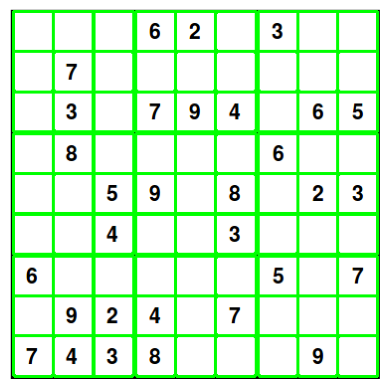

In [6]:
def contour_features(c):
    area = cv2.contourArea(c)
    x, y, w, h = cv2.boundingRect(c)
    hull_area = cv2.contourArea(cv2.convexHull(c))
    solidity = area / hull_area if hull_area > 0 else 0
    return area, solidity, w / float(h)

def is_cell(c):
    area, solidity, aspect_ratio = contour_features(c)
    return solidity > 0.9 and 0.8 < aspect_ratio < 1.2 and 1000 < area < 15000

cells = [c for c in contours if is_cell(c)]
cell_areas = [cv2.contourArea(c) for c in cells]
print(f"{len(cells)} of {len(contours)} contours kept as cells")
print(f"Cell areas between {min(cell_areas):.0f} and {max(cell_areas):.0f} px²")

preview = board.copy()
cv2.drawContours(preview, cells, -1, (0, 255, 0), 2)
show_image(preview)

## 4. Sort the cells

`findContours` returns contours in no particular order, but the board string must be read row by row. The function below, provided in the course material, sorts contours by the top-left corner of their bounding box: first by `y`, then by `x`.

It relies on every cell of a row having exactly the same `y`, which holds for these clean, computer-generated boards. A photographed or slightly rotated board would need a tolerance when grouping rows.

In [7]:
# Provided in the course material.
def sort_contours(cnts):
    boundingBoxes = [cv2.boundingRect(c) for c in cnts]
    (cnts, boundingBoxes) = zip(*sorted(zip(cnts, boundingBoxes), key=lambda b: (b[1][1], b[1][0]), reverse=False))
    return cnts

cells = sort_contours(cells)

## 5. Empty or filled?

Each cell is cropped with a 5-pixel margin on every side, so the grid lines around it are not included. In these boards an empty cell is then pure white, so any pixel below 255 means the cell contains a digit.

In [8]:
def cell_symbol(cell_crop):
    return "." if np.all(cell_crop == 255) else "?"

def crop_cell(image, c, margin=5):
    x, y, w, h = cv2.boundingRect(c)
    return image[y + margin:y + h - margin, x + margin:x + w - margin]

mask = "".join(cell_symbol(crop_cell(gray, c)) for c in cells)
print(mask)

...??.?...?........?.???.??.?....?....??.?.??..?..?...?.....?.?.???.?...????...?.


## 6. Complete function

The whole process as a single function, applied to the three boards. It checks that exactly 81 cells were found: otherwise the string would silently shift and every later step would read the wrong cells.

In [9]:
def find_cells(gray):
    thresh = cv2.threshold(gray, 30, 255, cv2.THRESH_BINARY_INV)[1]
    contours, _ = cv2.findContours(thresh, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    cells = [c for c in contours if is_cell(c)]
    if len(cells) != 81:
        raise ValueError(f"Expected 81 cells, found {len(cells)}")
    return sort_contours(cells)

def board_mask(image_path):
    gray = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2GRAY)
    return "".join(cell_symbol(crop_cell(gray, c)) for c in find_cells(gray))

def print_grid(board_string):
    for r in range(9):
        row = board_string[r * 9:(r + 1) * 9]
        print(" ".join(row[0:3]), "|", " ".join(row[3:6]), "|", " ".join(row[6:9]))
        if r in (2, 5):
            print("------+-------+------")

data/boards/sudoku1.png: 31 clues
...??.?...?........?.???.??.?....?....??.?.??..?..?...?.....?.?.???.?...????...?.
. . . | ? ? . | ? . .
. ? . | . . . | . . .
. ? . | ? ? ? | . ? ?
------+-------+------
. ? . | . . . | ? . .
. . ? | ? . ? | . ? ?
. . ? | . . ? | . . .
------+-------+------
? . . | . . . | ? . ?
. ? ? | ? . ? | . . .
? ? ? | ? . . | . ? .


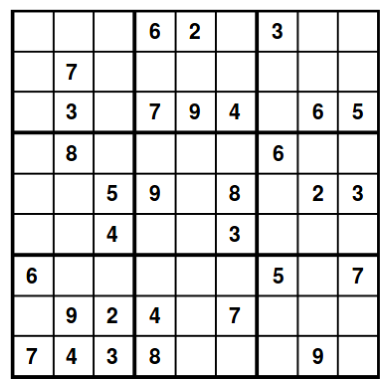

data/boards/sudoku2.png: 30 clues
.??..?.??.??.?....?...?......???..?..?....??.?....?.?.?.?..??....??.?.??....?....
. ? ? | . . ? | . ? ?
. ? ? | . ? . | . . .
? . . | . ? . | . . .
------+-------+------
. . ? | ? ? . | . ? .
. ? . | . . . | ? ? .
? . . | . . ? | . ? .
------+-------+------
? . ? | . . ? | ? . .
. . ? | ? . ? | . ? ?
. . . | . ? . | . . .


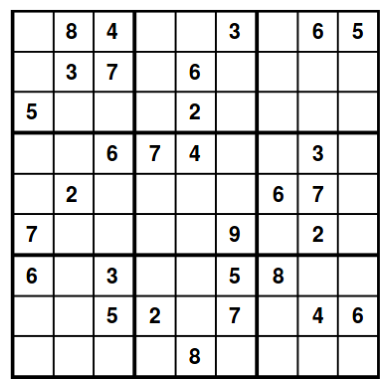

data/boards/sudoku3.png: 25 clues
...??..?.?....??.....?..........??.?.?...?.?...???.??.?.??............?..?....?.?
. . . | ? ? . | . ? .
? . . | . . ? | ? . .
. . . | ? . . | . . .
------+-------+------
. . . | . . ? | ? . ?
. ? . | . . ? | . ? .
. . ? | ? ? . | ? ? .
------+-------+------
? . ? | ? . . | . . .
. . . | . . . | . ? .
. ? . | . . . | ? . ?


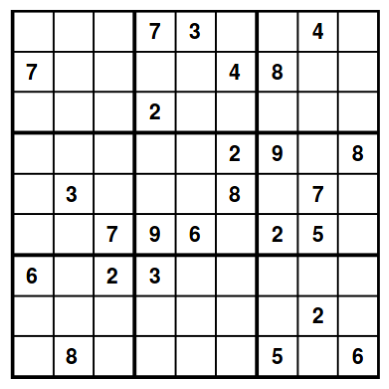

In [10]:
for path in BOARDS:
    mask = board_mask(path)
    print(f"{path}: {mask.count('?')} clues")
    print(mask)
    print_grid(mask)
    show_image(cv2.imread(path))

The three masks match their boards. Notebook 02 continues from here: it recognises the digit in each `?` cell, solves the puzzle and draws the solution on the image.